# 20 · Color Segmentation and Mask Quality

LRT4012 Robot Vision · Fall 2026


## HSV ranges isolate candidate colors

OpenCV represents 8-bit HSV as hue H in 0–179 and saturation S and value V in 0–255. Hue is circular: red may occupy both ends of H. Two red intervals are combined by logical OR. Low saturation makes hue unreliable; illumination and reflections can change all channels. Opening removes small foreground regions; closing fills small gaps, and both can alter object geometry.

## Metric definitions

For binary prediction $A$ and reference $B$, $TP=|A\cap B|$, $FP=|A\setminus B|$, and $FN=|B\setminus A|$ count true positives, false positives, and false negatives in pixels. The symbol $|\cdot|$ denotes set size.

$$\mathrm{IoU}=\frac{TP}{TP+FP+FN},\quad P=\frac{TP}{TP+FP},\quad R=\frac{TP}{TP+FN},\quad F_1=\frac{2TP}{2TP+FP+FN}.$$

$P$ is precision and $R$ is recall. Undefined precision or recall is reported as NaN. Two empty masks have IoU and F1 equal to one by convention. A reference produced by an algorithm measures agreement with that algorithm; it is not ground truth. Synthetic labels support controlled tests, but do not establish performance on real scenes.


In [1]:
from pathlib import Path
import os, time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_repository():
    candidates = []
    if os.environ.get('VISION_ROBOTICA_REPO'):
        candidates.append(Path(os.environ['VISION_ROBOTICA_REPO']).expanduser())
    candidates += [Path.cwd(), *Path.cwd().parents]
    for root in candidates:
        if (root / 'requirements.txt').is_file() and (root / 'imagenes').is_dir():
            return root.resolve()
    raise FileNotFoundError('Open Jupyter inside the course repository, or set VISION_ROBOTICA_REPO to its root.')

REPO = find_repository()
IMAGE_DIR = REPO / 'imagenes'  # Read-only official resources.
# Save your own notebook and generated images in student_work/ and student_work/imagenes/.
cv2.setRNGSeed(4012)
cv2.setNumThreads(1)
rng = np.random.default_rng(4012)
plt.rcParams.update({'figure.dpi':100, 'font.size':10})

def load_image(name, max_side=640):
    image = cv2.imread(str(IMAGE_DIR / name), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f'Official resource could not be read: {name}')
    h, w = image.shape[:2]
    if max(h, w) > max_side:
        scale = max_side / max(h, w)
        image = cv2.resize(image, (round(w*scale), round(h*scale)), interpolation=cv2.INTER_AREA)
    return image

def gray(image): return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

def panels(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(4*len(images), 3.5), squeeze=False)
    for ax, im, title in zip(axes[0], images, titles):
        if im.ndim == 3:
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(im, cmap='gray', vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis('off')
    fig.tight_layout()
    plt.show()

def timed_ms(fn, repetitions=30):
    fn()  # Warm-up.
    times = []
    for _ in range(repetitions):
        start = time.perf_counter()
        fn()
        times.append((time.perf_counter()-start)*1000)
    return float(np.median(times))

def mask_metrics(prediction, reference):
    a, b = prediction.astype(bool), reference.astype(bool)
    tp = int(np.count_nonzero(a & b))
    fp = int(np.count_nonzero(a & ~b))
    fn = int(np.count_nonzero(~a & b))
    return {'IoU': tp/(tp+fp+fn) if tp+fp+fn else 1.0,
            'precision': tp/(tp+fp) if tp+fp else np.nan,
            'recall': tp/(tp+fn) if tp+fn else np.nan,
            'F1': 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 1.0}


In [2]:
def object_scene(touching=False):
    image=np.full((240,360,3),220,np.uint8)
    labels=np.zeros((240,360),np.int32)
    centers=[(85,110),(137 if touching else 180,110),(275,140)]
    colors=[(40,40,190),(40,40,190),(40,155,40)]
    for i,(center,color) in enumerate(zip(centers,colors),start=1):
        mask=np.zeros(labels.shape,np.uint8)
        cv2.circle(mask,center,32,255,-1)
        labels[mask>0]=i; image[mask>0]=color
    return image,labels


,minimum_S,IoU,precision,recall,F1
0,50,1.0,1.0,1.0,1.0
1,130,1.0,1.0,1.0,1.0
2,220,0.0,NaN,0.0,0.0


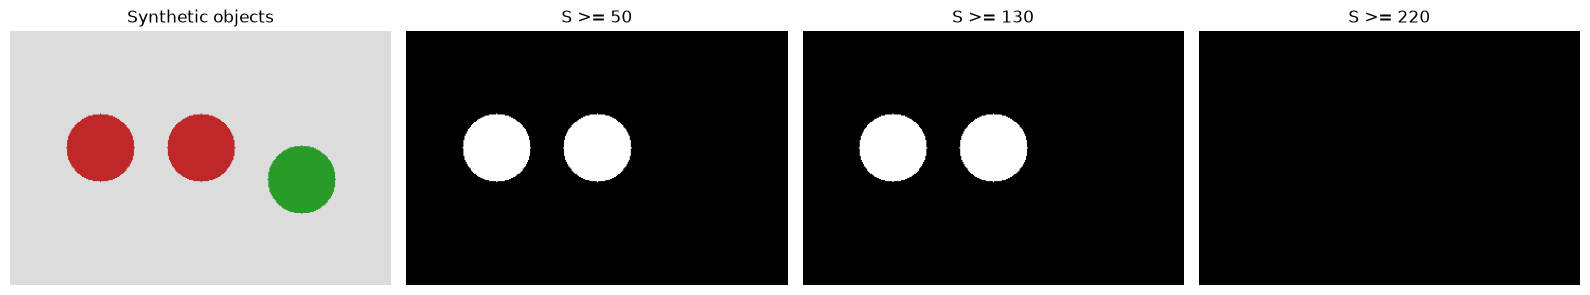

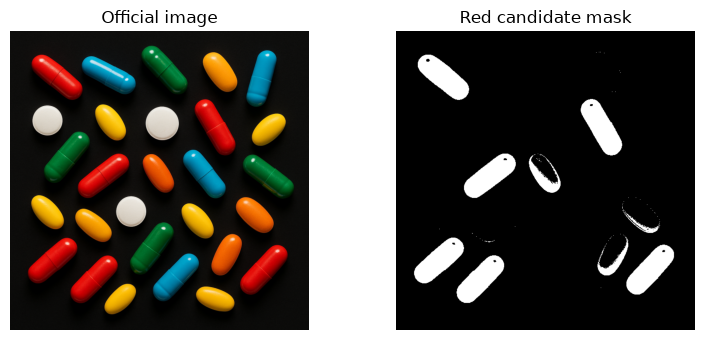

Real-image selected fraction: 0.08892578125


In [3]:
image,labels=object_scene(); hsv=cv2.cvtColor(image,cv2.COLOR_BGR2HSV)
reference=(labels==1)|(labels==2)
def red_mask(image,minimum_s=80):
    hsv=cv2.cvtColor(image,cv2.COLOR_BGR2HSV)
    return cv2.inRange(hsv,(0,minimum_s,40),(10,255,255)) | cv2.inRange(hsv,(170,minimum_s,40),(179,255,255))
rows=[]; masks=[]
for minimum_s in [50,130,220]:
    mask=red_mask(image,minimum_s)
    rows.append({'minimum_S':minimum_s,**mask_metrics(mask,reference)})
    masks.append(mask)
display(pd.DataFrame(rows).round(3))
panels([image,*masks],['Synthetic objects','S >= 50','S >= 130','S >= 220'])
real=load_image('pildoras2.png'); real_mask=red_mask(real)
panels([real,real_mask],['Official image','Red candidate mask'])
print('Real-image selected fraction:',float(np.mean(real_mask>0)))


## Robotic interpretation

Choose a mask for selecting red parts. Explain the distinction between selecting red pixels and counting red objects. Annotate a real-image reference before interpreting its selected fraction as quality.


## References

- [OpenCV: thresholding](https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html)
- [OpenCV: watershed](https://docs.opencv.org/4.13.0/d3/db4/tutorial_py_watershed.html)
- [OpenCV: contours](https://docs.opencv.org/4.x/d3/d05/tutorial_py_table_of_contents_contours.html)
